In [1]:
df = pd.read_csv("C:/Users/Lenovo/Downloads/merge_tcga_geo/ML_input_Basal_combined.csv", index_col=0)


NameError: name 'pd' is not defined

In [3]:
import pandas as pd

In [5]:
import numpy as np

In [13]:
df = pd.read_csv("C:/Users/Lenovo/Downloads/merge_tcga_geo/ML_input_Basal_combined.csv", index_col=0)

FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/Lenovo/Downloads/merge_tcga_geo/ML_input_Basal_combined.csv'

In [20]:
import os

In [22]:
folder = "C:/Users/Lenovo/Downloads/merge_tcga_geo"

In [24]:
print(os.path.exists(folder))

False


In [26]:
print(os.listdir(folder))

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:/Users/Lenovo/Downloads/merge_tcga_geo'

In [28]:
import os

In [32]:
downloads = "C:/Users/Lenovo/Downloads"

In [34]:
print(os.path.exists(downloads))

True


In [40]:
for item in os.listdir(downloads):
    print(item)

.Rhistory
1789199855265.jpg
bmed-14-04-015.pdf
Breast_cancer_project
Breast_cancer_project - Copy
desktop.ini
DJ2_1
DJ2_1 - Copy
Download_miccelineous
DOWNLOAD_SECTION_ALL_FOLDER
Format_of_Project_Report.doc
GEO
jpeg-optimizer_CompressJPEG.online_60kb_145142.jpg
Merge_GEO_TCGA
Public Service Commission, WB.pdf
Template_Poster_Biospectrum-2026.docx
WB Old Age Pension Form 2026.pdf
~$KPREPR_TABLE.docx
~$ST.docx
~WRL0195.tmp


In [47]:
folder = "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA"

In [49]:
print(os.path.exists(folder))

True


In [51]:
print(os.listdir(folder))

['.RDataTmp', '.RDataTmp1', '.Rhistory', 'Common_Genes_Basal.csv', 'Common_Genes_Her2.csv', 'Common_Genes_LumA.csv', 'Common_Genes_LumB.csv', 'DE_Basal_vs_Rest_Significant_GeneSymbols.csv', 'DE_Her2_vs_Rest_Significant_GeneSymbols.csv', 'DE_LumA_vs_Rest_Significant_GeneSymbols.csv', 'DE_LumB_vs_Rest_Significant_GeneSymbols.csv', 'GEO_combat_corrected_expression_matrix.csv', 'GEO_DEGs_filtered_Basal_vs_Rest.csv', 'GEO_DEGs_filtered_Her2_vs_Rest.csv', 'GEO_DEGs_filtered_LumA_vs_Rest.csv', 'GEO_DEGs_filtered_LumB_vs_Rest.csv', 'GEO_tumor_phenotype_labels.csv', 'ML_input_Basal_combined.csv', 'ML_input_Her2_combined.csv', 'ML_input_LumA_combined.csv', 'ML_input_LumB_combined.csv', 'ML_ready_datasets_all4subtypes.RData', 'TCGA_BRCA_logCPM_normalized.csv', 'TCGA_BRCA_subtype_labels.csv', 'TCGA_GEO_common_genes_per_subtype.RData']


In [53]:
import pandas as pd

In [59]:
import numpy as np

In [63]:
df = pd.read_csv("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_Basal_combined.csv", index_col=0)

In [73]:
print(df.shape)
print(df.columns[-2:])
print(df['Subtype'].value_counts())
print(df['Source'].value_counts())
print(df.isna().sum().sum())

(2065, 157)
Index(['Subtype', 'Source'], dtype='object')
Subtype
Rest     1530
Basal     535
Name: count, dtype: int64
Source
TCGA    1083
GEO      982
Name: count, dtype: int64
0


In [75]:
X = df.drop(columns=['Subtype', 'Source'])
y = df['Subtype']

In [77]:
print(X.shape)   # should be (2065, 155)
print(y.shape)   # should be (2065,)

(2065, 155)
(2065,)


In [79]:
# Encode the target labels as numbers (required for most ML models)
from sklearn.preprocessing import LabelEncoder

In [80]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [85]:
print(dict(zip(le.classes_, le.transform(le.classes_))))   # confirms which number = which label
# Scale the features (standardize to mean=0, std=1) - matches the paper's approach
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)


{'Basal': 0, 'Rest': 1}
(2065, 155)


In [89]:
def prepare_subtype_data(subtype_name, filepath):
    df = pd.read_csv(filepath, index_col=0)
    
    X = df.drop(columns=['Subtype', 'Source'])
    y = df['Subtype']
    
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Save as .npy/.pkl (fast reload for Python)
    np.save(f"{subtype_name}_X_scaled.npy", X_scaled)
    np.save(f"{subtype_name}_y_encoded.npy", y_encoded)
    with open(f"{subtype_name}_feature_names.pkl", "wb") as f:
        pickle.dump(X.columns.tolist(), f)
    with open(f"{subtype_name}_label_encoder.pkl", "wb") as f:
        pickle.dump(le, f)
    
    # Save as CSV too (human-readable, shareable)
    X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=df.index)
    X_scaled_df.to_csv(f"{subtype_name}_X_scaled.csv")
    
    y_df = pd.DataFrame({'Sample': df.index, 'Subtype_original': y, 'Subtype_encoded': y_encoded})
    y_df.to_csv(f"{subtype_name}_y.csv", index=False)
    
    print(f"{subtype_name}: X shape {X_scaled.shape}, classes: {dict(zip(le.classes_, le.transform(le.classes_)))}")
    
    return X_scaled, y_encoded

# Run for all 4 subtypes
X_basal, y_basal = prepare_subtype_data("Basal", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_Basal_combined.csv")
X_her2, y_her2   = prepare_subtype_data("Her2", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_Her2_combined.csv")
X_luma, y_luma   = prepare_subtype_data("LumA", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_LumA_combined.csv")
X_lumb, y_lumb   = prepare_subtype_data("LumB", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_LumB_combined.csv")

NameError: name 'pickle' is not defined

In [91]:
import pandas as pd
import numpy as np
import pickle
from sklearn.preprocessing import LabelEncoder, StandardScaler

def prepare_subtype_data(subtype_name, filepath):
    df = pd.read_csv(filepath, index_col=0)
    
    X = df.drop(columns=['Subtype', 'Source'])
    y = df['Subtype']
    
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    np.save(f"{subtype_name}_X_scaled.npy", X_scaled)
    np.save(f"{subtype_name}_y_encoded.npy", y_encoded)
    with open(f"{subtype_name}_feature_names.pkl", "wb") as f:
        pickle.dump(X.columns.tolist(), f)
    with open(f"{subtype_name}_label_encoder.pkl", "wb") as f:
        pickle.dump(le, f)
    
    X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=df.index)
    X_scaled_df.to_csv(f"{subtype_name}_X_scaled.csv")
    
    y_df = pd.DataFrame({'Sample': df.index, 'Subtype_original': y, 'Subtype_encoded': y_encoded})
    y_df.to_csv(f"{subtype_name}_y.csv", index=False)
    
    print(f"{subtype_name}: X shape {X_scaled.shape}, classes: {dict(zip(le.classes_, le.transform(le.classes_)))}")
    
    return X_scaled, y_encoded

X_basal, y_basal = prepare_subtype_data("Basal", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_Basal_combined.csv")
X_her2, y_her2   = prepare_subtype_data("Her2", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_Her2_combined.csv")
X_luma, y_luma   = prepare_subtype_data("LumA", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_LumA_combined.csv")
X_lumb, y_lumb   = prepare_subtype_data("LumB", "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA/ML_input_LumB_combined.csv")

Basal: X shape (2065, 155), classes: {'Basal': 0, 'Rest': 1}
Her2: X shape (2065, 27), classes: {'Her2': 0, 'Rest': 1}
LumA: X shape (2065, 47), classes: {'LumA': 0, 'Rest': 1}
LumB: X shape (2065, 24), classes: {'LumB': 0, 'Rest': 1}


In [93]:
import os
print(os.getcwd())   # shows current working directory - where files just saved

print(os.listdir())  # lists files in that current directory - look for Basal_X_scaled.npy etc

C:\Users\Lenovo
['.anaconda', '.cluegoplugin', '.conda', '.condarc', '.continuum', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.mgltools', '.ms-ad', '.ncbi', '.openjfx', '.pymol', '.virtual_documents', '.vscode', '.vscode-R', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Basal_feature_names.pkl', 'Basal_label_encoder.pkl', 'Basal_X_scaled.csv', 'Basal_X_scaled.npy', 'Basal_y.csv', 'Basal_y_encoded.npy', 'ClueGOConfiguration', 'CODE_WITH_HARRY_PRACTICE_PYTHON.ipynb', 'colorbar_degree.png', 'colorbar_degree.tiff', 'Contacts', 'Cookies', 'CytoscapeConfiguration', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'filtered_common_targets.xlsx', 'Her2_feature_names.pkl', 'Her2_label_encoder.pkl', 'Her2_X_scaled.csv', 'Her2_X_scaled.npy', 'Her2_y.csv', 'Her2_y_encoded.npy', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'LumA_feature_names.pkl', 'LumA_label_encoder.pkl', 'LumA_X_scaled.csv', 'LumA_X_scaled.npy', 'LumA_y.csv', 'LumA_y_enco

In [4]:
import os, pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
subtypes = ["Basal", "Her2", "LumA", "LumB"]
splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))
selected = pickle.load(open("selected_features.pkl", "rb"))
use_shortlist = {"Basal": True, "Her2": False, "LumA": True, "LumB": False}

rng = np.random.default_rng(42)
rows = []
for s in subtypes:
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    counts = selected[s][1]
    cols = counts[counts >= 3].index.tolist() if use_shortlist[s] else list(X_train.columns)
    y_pos = (y_test == 0).astype(int)   # 1 = the subtype itself

    models = {
        "LogReg": LogisticRegression(max_iter=2000, class_weight='balanced'),
        "RandomForest": RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                               random_state=42, n_jobs=-1),
    }
    for name, model in models.items():
        model.fit(X_train[cols], y_train)
        p = model.predict_proba(X_test[cols])[:, 0]   # probability of the subtype
        aucs, aps = [], []
        for _ in range(1000):
            idx = rng.integers(0, len(y_pos), len(y_pos))
            if y_pos[idx].sum() == 0:
                continue
            aucs.append(roc_auc_score(y_pos[idx], p[idx]))
            aps.append(average_precision_score(y_pos[idx], p[idx]))
        rows.append({
            "Subtype": s, "n_genes": len(cols), "Model": name,
            "AUC": round(roc_auc_score(y_pos, p), 3),
            "AUC_95CI": f"{np.percentile(aucs, 2.5):.3f} to {np.percentile(aucs, 97.5):.3f}",
            "AvgPrecision": round(average_precision_score(y_pos, p), 3),
            "AP_95CI": f"{np.percentile(aps, 2.5):.3f} to {np.percentile(aps, 97.5):.3f}",
        })

res = pd.DataFrame(rows)
res.to_csv("model_results_with_CI.csv", index=False)
print(res.to_string(index=False))

Subtype  n_genes        Model   AUC       AUC_95CI  AvgPrecision        AP_95CI
  Basal       31       LogReg 0.991 0.982 to 0.998         0.977 0.950 to 0.994
  Basal       31 RandomForest 0.992 0.981 to 0.999         0.985 0.969 to 0.996
   Her2       27       LogReg 0.976 0.957 to 0.991         0.839 0.721 to 0.927
   Her2       27 RandomForest 0.978 0.962 to 0.990         0.829 0.702 to 0.929
   LumA       12       LogReg 0.940 0.917 to 0.960         0.895 0.839 to 0.941
   LumA       12 RandomForest 0.947 0.925 to 0.966         0.917 0.871 to 0.951
   LumB       24       LogReg 0.887 0.851 to 0.918         0.572 0.468 to 0.693
   LumB       24 RandomForest 0.901 0.869 to 0.930         0.651 0.544 to 0.751


In [10]:
import os, pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
subtypes = ["Basal", "Her2", "LumA", "LumB"]
splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))
selected = pickle.load(open("selected_features.pkl", "rb"))
use_shortlist = {"Basal": True, "Her2": False, "LumA": True, "LumB": False}

def gene_cols(s):
    counts = selected[s][1]
    return counts[counts >= 3].index.tolist() if use_shortlist[s] else list(splits[s][0].columns)

# Check A: the same pooled model, scored separately on TCGA and GEO test samples
rows = []
for s in subtypes:
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    cols = gene_cols(s)
    model = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train[cols], y_train)
    p = model.predict_proba(X_test[cols])[:, 0]          # probability of the subtype
    y_pos = (y_test == 0).astype(int)
    src = np.where(X_test.index.str.startswith("TCGA-"), "TCGA", "GEO")
    for name in ["TCGA", "GEO"]:
        m = src == name
        rows.append({"Subtype": s, "Test_source": name, "n_test": int(m.sum()),
                     "n_subtype": int(y_pos[m].sum()),
                     "AUC": round(roc_auc_score(y_pos[m], p[m]), 3),
                     "AvgPrecision": round(average_precision_score(y_pos[m], p[m]), 3)})
print("A) Pooled model, scored per source")
print(pd.DataFrame(rows).to_string(index=False))

# Check B: train on one source, test on the other, with each gene z-scored within its own source
rows = []
for s in subtypes:
    df = pd.read_csv(f"ML_input_{s}_combined.csv", index_col=0)
    cols = gene_cols(s)
    y = (df["Subtype"] == s).astype(int)
    Xz = df[cols].groupby(df["Source"]).transform(lambda c: (c - c.mean()) / c.std())
    for tr_src, te_src in [("TCGA", "GEO"), ("GEO", "TCGA")]:
        tr = (df["Source"] == tr_src).values
        te = (df["Source"] == te_src).values
        model = LogisticRegression(max_iter=2000, class_weight='balanced').fit(Xz[tr], y[tr])
        p = model.predict_proba(Xz[te])[:, 1]
        rows.append({"Subtype": s, "Train": tr_src, "Test": te_src,
                     "AUC": round(roc_auc_score(y[te], p), 3),
                     "AvgPrecision": round(average_precision_score(y[te], p), 3),
                     "Chance_AP": round(y[te].mean(), 3)})
print("\nB) Cross-source")
print(pd.DataFrame(rows).to_string(index=False))

A) Pooled model, scored per source
Subtype Test_source  n_test  n_subtype   AUC  AvgPrecision
  Basal        TCGA     195         32 0.995         0.974
  Basal         GEO     218         75 0.988         0.986
   Her2        TCGA     213         14 0.995         0.936
   Her2         GEO     200         26 0.954         0.796
   LumA        TCGA     219        114 0.923         0.898
   LumA         GEO     194         65 0.952         0.903
   LumB        TCGA     190         39 0.872         0.536
   LumB         GEO     223         40 0.903         0.650

B) Cross-source
Subtype Train Test   AUC  AvgPrecision  Chance_AP
  Basal  TCGA  GEO 0.985         0.973      0.351
  Basal   GEO TCGA 0.996         0.986      0.175
   Her2  TCGA  GEO 0.928         0.768      0.121
   Her2   GEO TCGA 0.980         0.835      0.076
   LumA  TCGA  GEO 0.954         0.903      0.339
   LumA   GEO TCGA 0.932         0.905      0.519
   LumB  TCGA  GEO 0.881         0.599      0.188
   LumB   GEO TCG

In [13]:
import os, pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedShuffleSplit

DATA_DIR = "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA"
SUBTYPES = ["Basal", "Her2", "LumA", "LumB"]
USE_SHORTLIST = {"Basal": True, "Her2": False, "LumA": True, "LumB": False}  # same as before

# bootstrap settings
N_BOOT = 2000
SEED = 42

# stability-selection settings (used only for the leakage-free Check B)
# Adjust these to match what you used when you built selected_features.pkl.
N_ROUNDS = 50       # number of random subsamples
SUBSAMPLE = 0.5     # fraction of the training source used per round
L1_C = 0.1          # L1 strength; smaller = fewer genes survive
FREQ_CUTOFF = 0.6   # keep genes selected in >= 60% of rounds


# ---------- helpers ----------
def boot_ci(y, p, n_boot=N_BOOT, seed=SEED):
    """Point estimate + stratified-bootstrap 95% CI for AUC and average precision."""
    y = np.asarray(y).astype(int)
    p = np.asarray(p)
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    aucs, aps = [], []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        aucs.append(roc_auc_score(y[idx], p[idx]))
        aps.append(average_precision_score(y[idx], p[idx]))
    auc_lo, auc_hi = np.percentile(aucs, [2.5, 97.5])
    ap_lo, ap_hi = np.percentile(aps, [2.5, 97.5])
    auc, ap = roc_auc_score(y, p), average_precision_score(y, p)
    return {
        "AUC": round(auc, 3), "AUC_CI": f"{auc_lo:.3f}-{auc_hi:.3f}",
        "AP": round(ap, 3), "AP_CI": f"{ap_lo:.3f}-{ap_hi:.3f}",
    }


def load_combined(s):
    df = pd.read_csv(os.path.join(DATA_DIR, f"ML_input_{s}_combined.csv"), index_col=0)
    genes = [c for c in df.columns if c not in ("Subtype", "Source")]
    return df, genes


def zscore_within_source(df, genes):
    z = df[genes].groupby(df["Source"]).transform(lambda c: (c - c.mean()) / c.std())
    return z.fillna(0.0)


def stability_select(X, y, seed=SEED):
    """L1-logistic stability selection on ONE source only. Returns kept genes and frequencies."""
    sss = StratifiedShuffleSplit(n_splits=N_ROUNDS, train_size=SUBSAMPLE, random_state=seed)
    counts = np.zeros(X.shape[1])
    for tr, _ in sss.split(X, y):
        m = LogisticRegression(penalty="l1", solver="liblinear", C=L1_C,
                               class_weight="balanced", max_iter=2000)
        m.fit(X.iloc[tr], y.iloc[tr])
        counts += (m.coef_[0] != 0)
    freq = pd.Series(counts / N_ROUNDS, index=X.columns)
    keep = freq[freq >= FREQ_CUTOFF].index.tolist()
    if len(keep) < 5:  # safety net so the model never gets an empty/tiny gene set
        keep = freq.sort_values(ascending=False).index[:10].tolist()
    return keep, freq


# ---------- Check A with bootstrap CIs ----------
def check_a():
    splits = pickle.load(open(os.path.join(DATA_DIR, "splits_all4subtypes.pkl"), "rb"))
    selected = pickle.load(open(os.path.join(DATA_DIR, "selected_features.pkl"), "rb"))

    def gene_cols(s):
        counts = selected[s][1]
        return counts[counts >= 3].index.tolist() if USE_SHORTLIST[s] else list(splits[s][0].columns)

    rows = []
    for s in SUBTYPES:
        X_train, X_test, y_train, y_test, le, scaler = splits[s]
        cols = gene_cols(s)
        model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train[cols], y_train)
        p = model.predict_proba(X_test[cols])[:, 0]       # probability of the subtype (class 0)
        y_pos = (y_test == 0).astype(int)
        src = np.where(X_test.index.str.startswith("TCGA-"), "TCGA", "GEO")
        for name in ["TCGA", "GEO"]:
            m = src == name
            rows.append({"Subtype": s, "Test_source": name, "n_test": int(m.sum()),
                         "n_subtype": int(np.asarray(y_pos)[m].sum()),
                         **boot_ci(np.asarray(y_pos)[m], p[m])})
    return pd.DataFrame(rows)


# ---------- Check B (original gene lists) with bootstrap CIs ----------
def check_b_original():
    selected = pickle.load(open(os.path.join(DATA_DIR, "selected_features.pkl"), "rb"))
    rows = []
    for s in SUBTYPES:
        df, genes = load_combined(s)
        if USE_SHORTLIST[s]:
            counts = selected[s][1]
            genes = counts[counts >= 3].index.tolist()
        y = (df["Subtype"] == s).astype(int)
        Xz = zscore_within_source(df, genes)
        for tr_src, te_src in [("TCGA", "GEO"), ("GEO", "TCGA")]:
            tr, te = (df["Source"] == tr_src).values, (df["Source"] == te_src).values
            model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xz[tr], y[tr])
            p = model.predict_proba(Xz[te])[:, 1]
            rows.append({"Subtype": s, "Train": tr_src, "Test": te_src, "n_genes": len(genes),
                         **boot_ci(y[te], p), "Chance_AP": round(y[te].mean(), 3)})
    return pd.DataFrame(rows)


# ---------- Check B, leakage-free: gene selection inside the training source only ----------
def check_b_leakage_free():
    rows = []
    for s in SUBTYPES:
        df, genes = load_combined(s)
        y = (df["Subtype"] == s).astype(int)
        Xz = zscore_within_source(df, genes)
        for tr_src, te_src in [("TCGA", "GEO"), ("GEO", "TCGA")]:
            tr, te = (df["Source"] == tr_src).values, (df["Source"] == te_src).values
            if USE_SHORTLIST[s]:
                keep, _ = stability_select(Xz[tr], y[tr])   # uses training-source labels only
                how = "stability (train source only)"
            else:
                keep, how = genes, "all genes (no selection)"
            model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xz.loc[tr, keep], y[tr])
            p = model.predict_proba(Xz.loc[te, keep])[:, 1]
            rows.append({"Subtype": s, "Train": tr_src, "Test": te_src,
                         "Gene_set": how, "n_genes": len(keep),
                         **boot_ci(y[te], p), "Chance_AP": round(y[te].mean(), 3)})
    return pd.DataFrame(rows)


if __name__ == "__main__":
    os.chdir(DATA_DIR)
    outputs = [
        ("A) Pooled model, scored per source (with 95% CI)", check_a, "checkA_with_CI.csv"),
        ("B) Cross-source, original gene lists (with 95% CI)", check_b_original, "checkB_original_with_CI.csv"),
        ("B2) Cross-source, leakage-free gene selection (with 95% CI)", check_b_leakage_free,
         "checkB_leakage_free_with_CI.csv"),
    ]
    for title, fn, fname in outputs:
        res = fn()
        res.to_csv(fname, index=False)
        print("\n" + title)
        print(res.to_string(index=False))


A) Pooled model, scored per source (with 95% CI)
Subtype Test_source  n_test  n_subtype   AUC      AUC_CI    AP       AP_CI
  Basal        TCGA     195         32 0.995 0.987-1.000 0.974 0.929-1.000
  Basal         GEO     218         75 0.988 0.967-0.999 0.986 0.966-0.999
   Her2        TCGA     213         14 0.995 0.986-1.000 0.936 0.829-1.000
   Her2         GEO     200         26 0.954 0.909-0.987 0.796 0.654-0.927
   LumA        TCGA     219        114 0.923 0.883-0.956 0.898 0.835-0.953
   LumA         GEO     194         65 0.952 0.920-0.974 0.903 0.844-0.951
   LumB        TCGA     190         39 0.872 0.818-0.921 0.536 0.430-0.707
   LumB         GEO     223         40 0.903 0.856-0.942 0.650 0.525-0.787

B) Cross-source, original gene lists (with 95% CI)
Subtype Train Test  n_genes   AUC      AUC_CI    AP       AP_CI  Chance_AP
  Basal  TCGA  GEO       31 0.985 0.977-0.992 0.973 0.952-0.987      0.351
  Basal   GEO TCGA       31 0.996 0.993-0.999 0.986 0.975-0.994      0.17

In [15]:
import os, json, pickle, hashlib, datetime, platform
import numpy as np
import pandas as pd
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

DATA_DIR = "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA"
OUT_DIR = os.path.join(DATA_DIR, "final_model_v1")
SUBTYPES = ["Basal", "Her2", "LumA", "LumB"]
USE_SHORTLIST = {"Basal": True, "Her2": False, "LumA": True, "LumB": False}  # same as the validated pipeline

os.makedirs(OUT_DIR, exist_ok=True)
os.chdir(DATA_DIR)

selected = pickle.load(open("selected_features.pkl", "rb"))


def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


meta = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "sklearn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "python": platform.python_version(),
    "description": "One-vs-rest breast cancer subtype classifiers (LogReg, class_weight=balanced) "
                   "trained on all TCGA+GEO (ComBat-corrected) samples; scaling bundled in pipeline.",
    "input_requirement": "Expression must be preprocessed exactly like ML_input_*_combined.csv "
                         "(same normalisation + batch correction, gene symbols as columns).",
    "subtypes": {},
}

for s in SUBTYPES:
    path = f"ML_input_{s}_combined.csv"
    df = pd.read_csv(path, index_col=0)
    all_genes = [c for c in df.columns if c not in ("Subtype", "Source")]
    if USE_SHORTLIST[s]:
        counts = selected[s][1]
        genes = [g for g in counts[counts >= 3].index.tolist() if g in all_genes]
    else:
        genes = all_genes
    y = (df["Subtype"] == s).astype(int)

    model = Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ]).fit(df[genes], y)

    joblib.dump(model, os.path.join(OUT_DIR, f"model_{s}.joblib"))
    with open(os.path.join(OUT_DIR, f"genes_{s}.json"), "w") as f:
        json.dump(genes, f)

    # reference predictions for a reload sanity check
    ref = model.predict_proba(df[genes])[:, 1]
    np.save(os.path.join(OUT_DIR, f"ref_probs_{s}.npy"), ref)

    meta["subtypes"][s] = {
        "n_genes": len(genes),
        "n_train": int(len(df)),
        "n_positive": int(y.sum()),
        "positive_class": 1,
        "training_file": path,
        "training_file_md5": md5(path),
    }
    print(f"{s}: {len(genes)} genes, {len(df)} samples, {int(y.sum())} positives -> saved")

with open(os.path.join(OUT_DIR, "metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# ---------- reload check ----------
for s in SUBTYPES:
    df = pd.read_csv(f"ML_input_{s}_combined.csv", index_col=0)
    m = joblib.load(os.path.join(OUT_DIR, f"model_{s}.joblib"))
    genes = json.load(open(os.path.join(OUT_DIR, f"genes_{s}.json")))
    ref = np.load(os.path.join(OUT_DIR, f"ref_probs_{s}.npy"))
    assert np.allclose(m.predict_proba(df[genes])[:, 1], ref), f"reload mismatch for {s}"
print("Reload check passed: saved models reproduce the reference predictions.")


# ---------- how to use the frozen models on new samples ----------
def predict_subtypes(expr, out_dir=OUT_DIR):
    """expr: DataFrame, rows = samples, columns = gene symbols, preprocessed like the training data.
    Returns a DataFrame of one-vs-rest probabilities and the top-scoring subtype."""
    probs = {}
    for s in SUBTYPES:
        m = joblib.load(os.path.join(out_dir, f"model_{s}.joblib"))
        genes = json.load(open(os.path.join(out_dir, f"genes_{s}.json")))
        missing = [g for g in genes if g not in expr.columns]
        if missing:
            raise ValueError(f"{s}: {len(missing)} required genes missing, e.g. {missing[:5]}")
        probs[s] = m.predict_proba(expr[genes])[:, 1]
    out = pd.DataFrame(probs, index=expr.index)
    out["Top_subtype"] = out[SUBTYPES].idxmax(axis=1)
    return out

Basal: 31 genes, 2065 samples, 535 positives -> saved
Her2: 27 genes, 2065 samples, 201 positives -> saved
LumA: 12 genes, 2065 samples, 895 positives -> saved
LumB: 24 genes, 2065 samples, 394 positives -> saved
Reload check passed: saved models reproduce the reference predictions.


In [2]:
import os, pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
subtypes = ["Basal", "Her2", "LumA", "LumB"]
splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))
selected = pickle.load(open("selected_features.pkl", "rb"))

tables = []
for s in subtypes:
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    cols = list(X_train.columns)
    counts = selected[s][1]
    lr = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train[cols], y_train)
    tab = pd.DataFrame({
        "Subtype": s,
        "Gene": cols,
        "Votes": counts.reindex(cols).values,
        "LogReg_coef_toward_subtype": -lr.coef_[0],
        "Mean_z_diff": (X_train.loc[y_train == 0, cols].mean() - X_train.loc[y_train == 1, cols].mean()).values,
    })
    tab["Direction"] = np.where(tab["Mean_z_diff"] > 0, "higher in subtype", "lower in subtype")
    tab["In_shortlist"] = tab["Votes"] >= 3
    tab["abs_coef"] = tab["LogReg_coef_toward_subtype"].abs()
    tables.append(tab.sort_values(["Votes", "abs_coef"], ascending=False).drop(columns="abs_coef"))

final = pd.concat(tables)
final.to_csv("final_gene_tables_all4subtypes.csv", index=False)
print(final.groupby("Subtype")["In_shortlist"].sum())
print(final[final.In_shortlist].groupby("Subtype").head(5)[["Subtype", "Gene", "Votes", "Direction"]].to_string(index=False))

Subtype
Basal    31
Her2      7
LumA     12
LumB      8
Name: In_shortlist, dtype: int64
Subtype   Gene  Votes         Direction
  Basal    EN1      3 higher in subtype
  Basal   AGR2      3  lower in subtype
  Basal  MCCC2      3  lower in subtype
  Basal   MLPH      3  lower in subtype
  Basal  FOXA1      3  lower in subtype
   Her2  NPY1R      3  lower in subtype
   Her2   FA2H      3 higher in subtype
   Her2 ABCA12      3 higher in subtype
   Her2   PNMT      3 higher in subtype
   Her2 SCUBE2      3  lower in subtype
   LumA  CCNB2      3  lower in subtype
   LumA SCUBE2      3 higher in subtype
   LumA   LRP8      3  lower in subtype
   LumA    PGR      3 higher in subtype
   LumA    TTK      3  lower in subtype
   LumB  SFRP1      3  lower in subtype
   LumB  ANXA3      3  lower in subtype
   LumB  KRT15      3  lower in subtype
   LumB  CRYAB      3  lower in subtype
   LumB   SLPI      3  lower in subtype


In [4]:
import os, pickle, joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
subtypes = ["Basal", "Her2", "LumA", "LumB"]
splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))
selected = pickle.load(open("selected_features.pkl", "rb"))
cv = StratifiedKFold(5, shuffle=True, random_state=42)

def make_model(kind):
    if kind == "LogReg":
        return LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=5, scoring="average_precision",
                                    class_weight="balanced", max_iter=3000)
    return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=42, n_jobs=-1)

def metrics_at(y, p, thr):
    pr = (p >= thr).astype(int)
    return {"AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p),
            "F1": f1_score(y, pr, zero_division=0),
            "Precision": precision_score(y, pr, zero_division=0),
            "Recall": recall_score(y, pr, zero_division=0)}

def boot_report(y, p, thr, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    draws = {k: [] for k in ["AUC", "AP", "F1", "Precision", "Recall"]}
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        for k, v in metrics_at(y[idx], p[idx], thr).items():
            draws[k].append(v)
    point = metrics_at(y, p, thr)
    return {k: f"{point[k]:.3f} ({np.percentile(draws[k], 2.5):.3f}-{np.percentile(draws[k], 97.5):.3f})"
            for k in point}

cv_rows, final_rows, store = [], [], {}
for s in subtypes:
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    ytr = (y_train == 0).astype(int)      # 1 = the subtype itself
    yte = (y_test == 0).astype(int)
    counts = selected[s][1]
    gene_sets = {"shortlist": counts[counts >= 3].index.tolist(), "all": list(X_train.columns)}

    # 1) choose gene set + model type by training-only CV (average precision for the subtype)
    best = None
    for gs, genes in gene_sets.items():
        for kind in ["LogReg", "RandomForest"]:
            score = cross_val_score(make_model(kind), X_train[genes], ytr, cv=cv,
                                    scoring="average_precision").mean()
            cv_rows.append({"Subtype": s, "Gene_set": gs, "n_genes": len(genes),
                            "Model": kind, "CV_AP": round(score, 3)})
            if best is None or score > best[0]:
                best = (score, gs, kind)
    _, best_gs, best_kind = best
    genes = gene_sets[best_gs]

    # 2) pick the decision threshold from out-of-fold training predictions (max F1)
    oof = cross_val_predict(make_model(best_kind), X_train[genes], ytr, cv=cv,
                            method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(ytr, oof)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    threshold = float(thr[np.argmax(f1s)])

    # 3) fit on the training split and score the test set once
    model = make_model(best_kind).fit(X_train[genes], ytr)
    p = model.predict_proba(X_test[genes])[:, 1]
    final_rows.append({"Subtype": s, "Model": best_kind, "Gene_set": best_gs, "n_genes": len(genes),
                       "Threshold": round(threshold, 3), "n_test": len(yte), "n_pos": int(yte.sum()),
                       **boot_report(yte, p, threshold)})

    # 4) save the exact model that was evaluated, plus a gene table
    joblib.dump({"subtype": s, "model": model, "model_type": best_kind, "genes": genes,
                 "threshold": threshold, "scaler": scaler,
                 "candidate_genes": list(X_train.columns)}, f"FINAL_model_{s}.joblib")
    weights = model.coef_[0] if best_kind == "LogReg" else model.feature_importances_
    pd.DataFrame({"Gene": genes, "Weight": weights}).sort_values(
        "Weight", key=abs, ascending=False).to_csv(f"FINAL_{s}_gene_weights.csv", index=False)
    store[s] = (yte, p, threshold, X_test.index)

cv_table = pd.DataFrame(cv_rows)
final_table = pd.DataFrame(final_rows)
cv_table.to_csv("FINAL_training_CV_comparison.csv", index=False)
final_table.to_csv("FINAL_test_results.csv", index=False)
print(cv_table.to_string(index=False))
print()
print(final_table.to_string(index=False))

Subtype  Gene_set  n_genes        Model  CV_AP
  Basal shortlist       31       LogReg  0.987
  Basal shortlist       31 RandomForest  0.984
  Basal       all      155       LogReg  0.987
  Basal       all      155 RandomForest  0.985
   Her2 shortlist        7       LogReg  0.721
   Her2 shortlist        7 RandomForest  0.767
   Her2       all       27       LogReg  0.808
   Her2       all       27 RandomForest  0.840
   LumA shortlist       12       LogReg  0.910
   LumA shortlist       12 RandomForest  0.914
   LumA       all       47       LogReg  0.919
   LumA       all       47 RandomForest  0.949
   LumB shortlist        8       LogReg  0.593
   LumB shortlist        8 RandomForest  0.591
   LumB       all       24       LogReg  0.614
   LumB       all       24 RandomForest  0.646

Subtype        Model Gene_set  n_genes  Threshold  n_test  n_pos                 AUC                  AP                  F1           Precision              Recall
  Basal       LogReg      all      

In [5]:
USE_SHORTLIST = {s: False for s in SUBTYPES}
print(check_a().to_string(index=False))
print(check_b_original().to_string(index=False))

NameError: name 'SUBTYPES' is not defined

Basal confusion matrix [[TN, FP], [FN, TP]]: [[305, 1], [7, 100]]
Her2 confusion matrix [[TN, FP], [FN, TP]]: [[363, 10], [11, 29]]
LumA confusion matrix [[TN, FP], [FN, TP]]: [[210, 24], [15, 164]]
LumB confusion matrix [[TN, FP], [FN, TP]]: [[284, 50], [18, 61]]


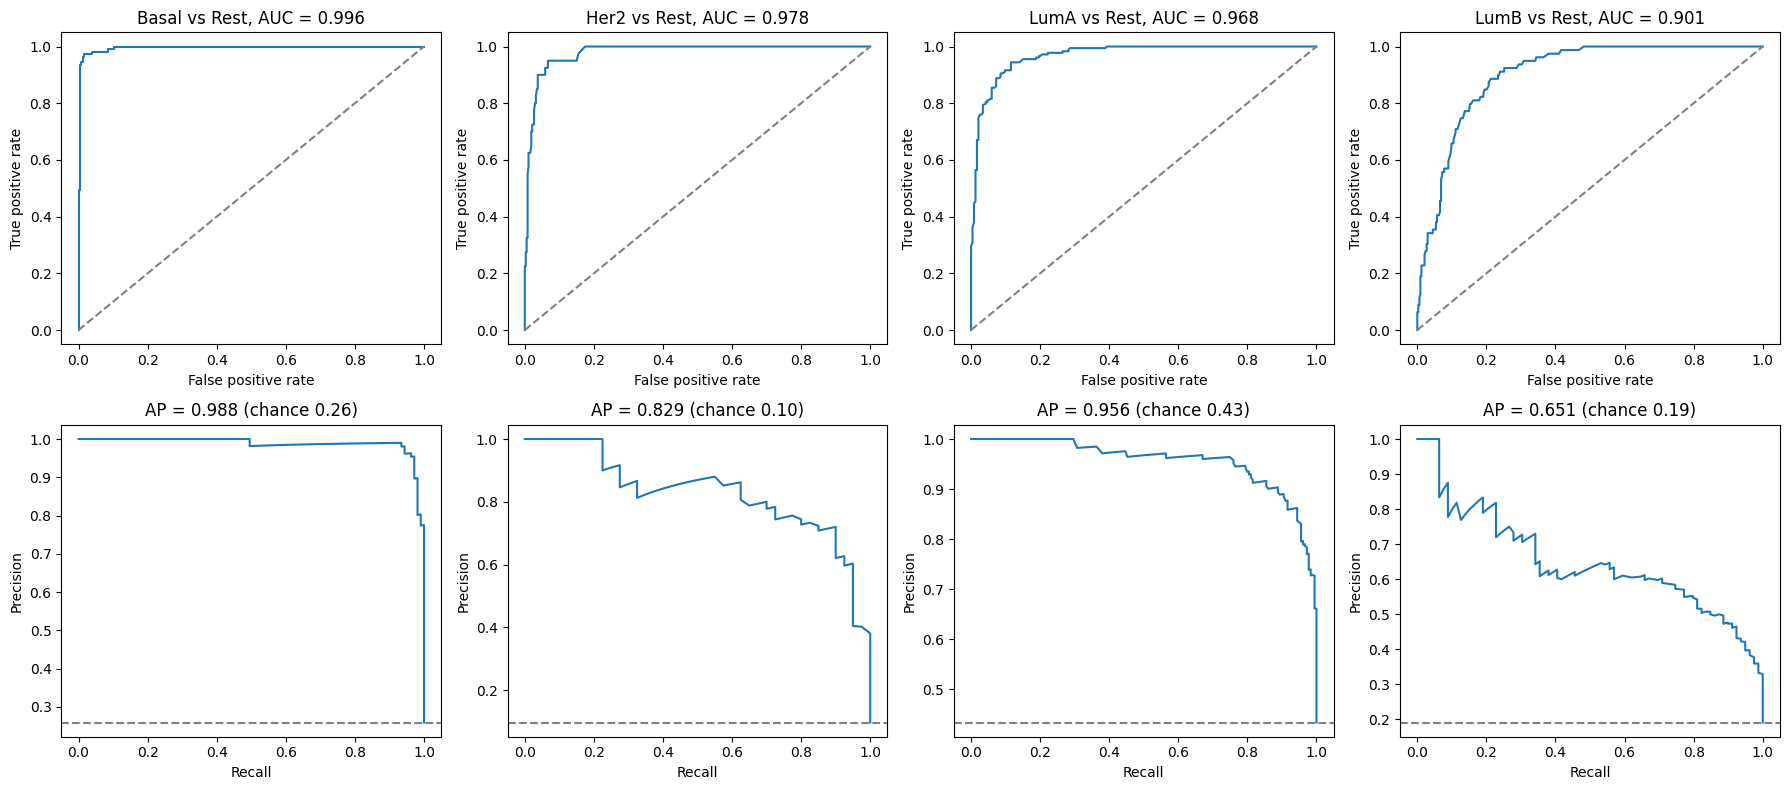

In [8]:
import os, pickle, joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, confusion_matrix)

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
subtypes = ["Basal", "Her2", "LumA", "LumB"]
splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, s in enumerate(subtypes):
    bundle = joblib.load(f"FINAL_model_{s}.joblib")
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    yte = (y_test == 0).astype(int)
    p = bundle["model"].predict_proba(X_test[bundle["genes"]])[:, 1]

    fpr, tpr, _ = roc_curve(yte, p)
    axes[0, j].plot(fpr, tpr)
    axes[0, j].plot([0, 1], [0, 1], "--", color="grey")
    axes[0, j].set_title(f"{s} vs Rest, AUC = {roc_auc_score(yte, p):.3f}")
    axes[0, j].set_xlabel("False positive rate")
    axes[0, j].set_ylabel("True positive rate")

    prec, rec, _ = precision_recall_curve(yte, p)
    axes[1, j].plot(rec, prec)
    axes[1, j].axhline(yte.mean(), ls="--", color="grey")
    axes[1, j].set_title(f"AP = {average_precision_score(yte, p):.3f} (chance {yte.mean():.2f})")
    axes[1, j].set_xlabel("Recall")
    axes[1, j].set_ylabel("Precision")

    cm = confusion_matrix(yte, (p >= bundle["threshold"]).astype(int))
    print(s, "confusion matrix [[TN, FP], [FN, TP]]:", cm.tolist())

plt.tight_layout()
plt.savefig("FINAL_ROC_PR_curves.png", dpi=300)
plt.show()

In [12]:
import os, pickle, joblib
import numpy as np
import pandas as pd

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
subtypes = ["Basal", "Her2", "LumA", "LumB"]
splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))

tcga_lab = pd.read_csv("TCGA_BRCA_subtype_labels.csv").set_index("patient")["subtype"]
geo_lab = pd.read_csv("GEO_tumor_phenotype_labels.csv").set_index("Sample_ID")["Subtype"]
true_sub = pd.concat([tcga_lab, geo_lab])

for s in subtypes:
    bundle = joblib.load(f"FINAL_model_{s}.joblib")
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    p = bundle["model"].predict_proba(X_test[bundle["genes"]])[:, 1]
    flagged = p >= bundle["threshold"]
    is_pos = (y_test == 0)
    fp_ids = X_test.index[flagged & ~is_pos]
    print(s, "false alarms by true subtype:",
          true_sub.reindex(fp_ids).fillna("unknown").value_counts().to_dict())

Basal false alarms by true subtype: {'Normal': 1}
Her2 false alarms by true subtype: {'Basal': 5, 'LumA': 2, 'LumB': 2, 'Normal': 1}
LumA false alarms by true subtype: {'LumB': 16, 'Normal': 5, 'Her2': 2, 'Basal': 1}
LumB false alarms by true subtype: {'LumA': 43, 'Her2': 6, 'Basal': 1}


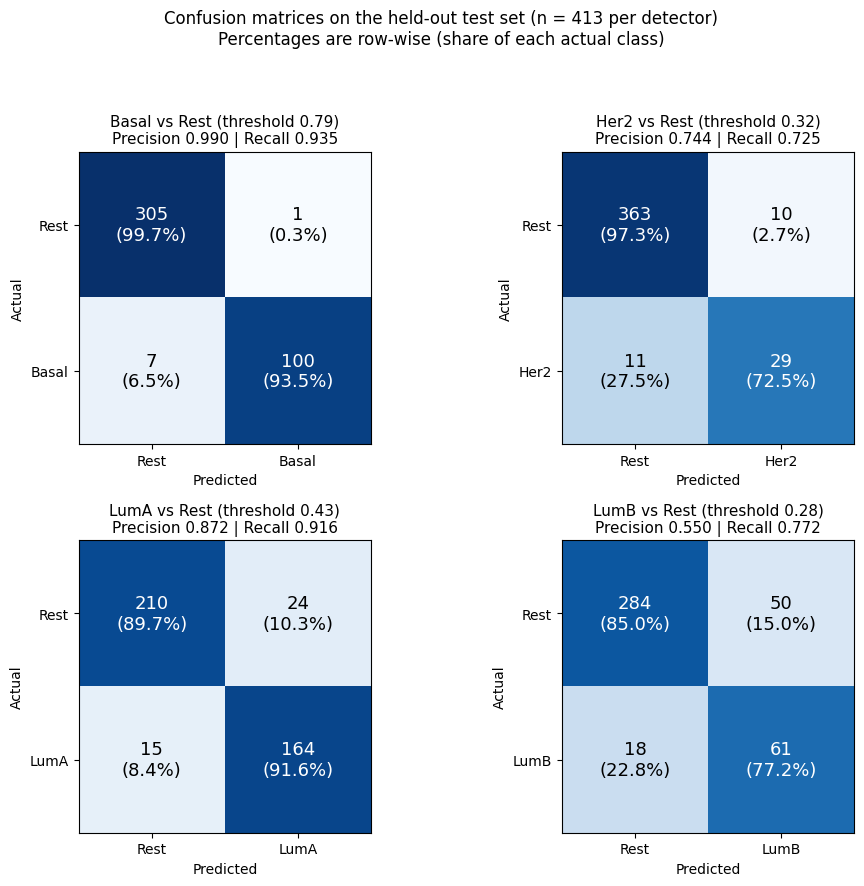

['.RDataTmp', '.RDataTmp1', '.Rhistory', 'Basal_feature_names.pkl', 'Basal_feature_selection_counts.csv', 'Basal_label_encoder.pkl', 'Basal_top_RF_genes.csv', 'Basal_X_scaled.csv', 'Basal_X_scaled.npy', 'Basal_y.csv', 'Basal_y_encoded.npy', 'brca_subtype_4class_logreg.joblib', 'brca_subtype_multiclass_logreg.joblib', 'checkA_with_CI.csv', 'checkB_leakage_free_with_CI.csv', 'checkB_original_with_CI.csv', 'Common_Genes_Basal.csv', 'Common_Genes_Her2.csv', 'Common_Genes_LumA.csv', 'Common_Genes_LumB.csv', 'Confusion_matrices_all4.png', 'Confusion_matrix_Basal.png', 'confusion_matrix_cv.png', 'Confusion_matrix_Her2.png', 'Confusion_matrix_LumA.png', 'Confusion_matrix_LumB.png', 'cross_source_normalisation.csv', 'DE_Basal_vs_Rest_Significant_GeneSymbols.csv', 'DE_Her2_vs_Rest_Significant_GeneSymbols.csv', 'DE_LumA_vs_Rest_Significant_GeneSymbols.csv', 'DE_LumB_vs_Rest_Significant_GeneSymbols.csv', 'FINAL_Basal_gene_weights.csv', 'final_gene_tables_all4subtypes.csv', 'FINAL_Her2_gene_weights

In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")

cms = {
    "Basal": ([[305, 1], [7, 100]], 0.793),
    "Her2":  ([[363, 10], [11, 29]], 0.320),
    "LumA":  ([[210, 24], [15, 164]], 0.433),
    "LumB":  ([[284, 50], [18, 61]], 0.277),
}

def draw(ax, s, cm, thr):
    cm = np.array(cm)
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            color = "white" if row_pct[i, j] > 0.5 else "black"
            ax.text(j, i, f"{cm[i, j]}\n({row_pct[i, j]*100:.1f}%)",
                    ha="center", va="center", fontsize=13, color=color)
    tn, fp, fn, tp = cm.ravel()
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Rest", s]); ax.set_yticklabels(["Rest", s])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{s} vs Rest (threshold {thr:.2f})\nPrecision {tp/(tp+fp):.3f} | Recall {tp/(tp+fn):.3f}", fontsize=11)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (s, (cm, thr)) in zip(axes.ravel(), cms.items()):
    draw(ax, s, cm, thr)
fig.suptitle("Confusion matrices on the held-out test set (n = 413 per detector)\nPercentages are row-wise (share of each actual class)", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("Confusion_matrices_all4.png", dpi=300)
plt.show()

for s, (cm, thr) in cms.items():
    fig, ax = plt.subplots(figsize=(5, 4.6))
    draw(ax, s, cm, thr)
    plt.tight_layout()
    plt.savefig(f"Confusion_matrix_{s}.png", dpi=300)
    plt.close()

print(os.listdir())

In [22]:
import sys, sklearn, numpy, pandas, joblib
print(sys.version.split()[0], "| sklearn", sklearn.__version__, "| numpy", numpy.__version__,
      "| pandas", pandas.__version__, "| joblib", joblib.__version__)

3.12.7 | sklearn 1.5.1 | numpy 1.26.4 | pandas 2.2.2 | joblib 1.4.2


In [24]:
USE_SHORTLIST = {s: False for s in SUBTYPES}

NameError: name 'SUBTYPES' is not defined

In [26]:
import os, pickle, joblib
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

os.chdir("C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
subtypes = ["Basal", "Her2", "LumA", "LumB"]
splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))
lab = pd.read_csv("TCGA_BRCA_subtype_labels.csv")
normal_ids = set(lab.loc[lab["subtype"] == "Normal", "patient"])

rows = []
for s in subtypes:
    b = joblib.load(f"FINAL_model_{s}.joblib")
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    y = (y_test == 0).astype(int)
    p = b["model"].predict_proba(X_test[b["genes"]])[:, 1]
    pred = (p >= b["threshold"]).astype(int)
    is_normal = X_test.index.isin(normal_ids)
    for name, m in [("all test samples", np.ones(len(y), bool)), ("without TCGA Normal-like", ~is_normal)]:
        rows.append({"Subtype": s, "Test_set": name, "n": int(m.sum()), "n_pos": int(y[m].sum()),
                     "AUC": round(roc_auc_score(y[m], p[m]), 3),
                     "AP": round(average_precision_score(y[m], p[m]), 3),
                     "F1": round(f1_score(y[m], pred[m]), 3),
                     "Precision": round(precision_score(y[m], pred[m]), 3),
                     "Recall": round(recall_score(y[m], pred[m]), 3)})
print(pd.DataFrame(rows).to_string(index=False))

Subtype                 Test_set   n  n_pos   AUC    AP    F1  Precision  Recall
  Basal         all test samples 413    107 0.996 0.988 0.962      0.990   0.935
  Basal without TCGA Normal-like 403    107 0.998 0.995 0.966      1.000   0.935
   Her2         all test samples 413     40 0.978 0.829 0.734      0.744   0.725
   Her2 without TCGA Normal-like 406     40 0.979 0.835 0.744      0.763   0.725
   LumA         all test samples 413    179 0.968 0.956 0.894      0.872   0.916
   LumA without TCGA Normal-like 404    179 0.976 0.969 0.906      0.896   0.916
   LumB         all test samples 413     79 0.901 0.651 0.642      0.550   0.772
   LumB without TCGA Normal-like 404     79 0.899 0.651 0.642      0.550   0.772


In [28]:
import os, pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

DATA_DIR = "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA"
os.chdir(DATA_DIR)
SUBTYPES = ["Basal", "Her2", "LumA", "LumB"]
N_BOOT, SEED = 2000, 42

def boot_ci(y, p, n_boot=N_BOOT, seed=SEED):
    y = np.asarray(y).astype(int); p = np.asarray(p)
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    aucs, aps = [], []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        aucs.append(roc_auc_score(y[idx], p[idx]))
        aps.append(average_precision_score(y[idx], p[idx]))
    return {"AUC": round(roc_auc_score(y, p), 3),
            "AUC_CI": f"{np.percentile(aucs, 2.5):.3f}-{np.percentile(aucs, 97.5):.3f}",
            "AP": round(average_precision_score(y, p), 3),
            "AP_CI": f"{np.percentile(aps, 2.5):.3f}-{np.percentile(aps, 97.5):.3f}"}

def zscore_within_source(df, genes):
    z = df[genes].groupby(df["Source"]).transform(lambda c: (c - c.mean()) / c.std())
    return z.fillna(0.0)

splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))

# Check A: pooled model (all genes), scored separately on TCGA and GEO test samples
rows = []
for s in SUBTYPES:
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    cols = list(X_train.columns)
    model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train[cols], y_train)
    p = model.predict_proba(X_test[cols])[:, 0]          # probability of the subtype
    y_pos = (y_test == 0).astype(int)
    src = np.where(X_test.index.str.startswith("TCGA-"), "TCGA", "GEO")
    for name in ["TCGA", "GEO"]:
        m = src == name
        rows.append({"Subtype": s, "Test_source": name, "n_test": int(m.sum()),
                     "n_subtype": int(y_pos[m].sum()), **boot_ci(y_pos[m], p[m])})
res_a = pd.DataFrame(rows)
res_a.to_csv("checkA_all_genes_with_CI.csv", index=False)
print("A) Pooled model, all genes, scored per source")
print(res_a.to_string(index=False))

# Check B: train on one source, test on the other, genes z-scored within each source
rows = []
for s in SUBTYPES:
    df = pd.read_csv(f"ML_input_{s}_combined.csv", index_col=0)
    genes = [c for c in df.columns if c not in ("Subtype", "Source")]
    y = (df["Subtype"] == s).astype(int)
    Xz = zscore_within_source(df, genes)
    for tr_src, te_src in [("TCGA", "GEO"), ("GEO", "TCGA")]:
        tr, te = (df["Source"] == tr_src).values, (df["Source"] == te_src).values
        model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xz[tr], y[tr])
        p = model.predict_proba(Xz[te])[:, 1]
        rows.append({"Subtype": s, "Train": tr_src, "Test": te_src, "n_genes": len(genes),
                     **boot_ci(y[te], p), "Chance_AP": round(y[te].mean(), 3)})
res_b = pd.DataFrame(rows)
res_b.to_csv("checkB_all_genes_with_CI.csv", index=False)
print("\nB) Cross-source, all genes")
print(res_b.to_string(index=False))

A) Pooled model, all genes, scored per source
Subtype Test_source  n_test  n_subtype   AUC      AUC_CI    AP       AP_CI
  Basal        TCGA     195         32 0.998 0.992-1.000 0.991 0.970-1.000
  Basal         GEO     218         75 0.994 0.984-1.000 0.992 0.978-1.000
   Her2        TCGA     213         14 0.995 0.986-1.000 0.936 0.829-1.000
   Her2         GEO     200         26 0.954 0.909-0.987 0.796 0.654-0.927
   LumA        TCGA     219        114 0.924 0.885-0.958 0.891 0.830-0.956
   LumA         GEO     194         65 0.951 0.917-0.975 0.911 0.853-0.957
   LumB        TCGA     190         39 0.872 0.818-0.921 0.536 0.430-0.707
   LumB         GEO     223         40 0.903 0.856-0.942 0.650 0.525-0.787

B) Cross-source, all genes
Subtype Train Test  n_genes   AUC      AUC_CI    AP       AP_CI  Chance_AP
  Basal  TCGA  GEO      155 0.989 0.983-0.994 0.976 0.956-0.989      0.351
  Basal   GEO TCGA      155 0.997 0.994-0.999 0.987 0.977-0.994      0.175
   Her2  TCGA  GEO       2

In [2]:
import os, pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

DATA_DIR = "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA"
os.chdir(DATA_DIR)
SUBTYPES = ["Basal", "Her2", "LumA", "LumB"]
N_BOOT, SEED = 2000, 42

def boot_ci(y, p, n_boot=N_BOOT, seed=SEED):
    y = np.asarray(y).astype(int); p = np.asarray(p)
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    aucs, aps = [], []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        aucs.append(roc_auc_score(y[idx], p[idx]))
        aps.append(average_precision_score(y[idx], p[idx]))
    return {"AUC": round(roc_auc_score(y, p), 3),
            "AUC_CI": f"{np.percentile(aucs, 2.5):.3f}-{np.percentile(aucs, 97.5):.3f}",
            "AP": round(average_precision_score(y, p), 3),
            "AP_CI": f"{np.percentile(aps, 2.5):.3f}-{np.percentile(aps, 97.5):.3f}"}

def zscore_within_source(df, genes):
    z = df[genes].groupby(df["Source"]).transform(lambda c: (c - c.mean()) / c.std())
    return z.fillna(0.0)

splits = pickle.load(open("splits_all4subtypes.pkl", "rb"))

# Check A: pooled model (all genes), scored separately on TCGA and GEO test samples
rows = []
for s in SUBTYPES:
    X_train, X_test, y_train, y_test, le, scaler = splits[s]
    cols = list(X_train.columns)
    model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train[cols], y_train)
    p = model.predict_proba(X_test[cols])[:, 0]          # probability of the subtype
    y_pos = (y_test == 0).astype(int)
    src = np.where(X_test.index.str.startswith("TCGA-"), "TCGA", "GEO")
    for name in ["TCGA", "GEO"]:
        m = src == name
        rows.append({"Subtype": s, "Test_source": name, "n_test": int(m.sum()),
                     "n_subtype": int(y_pos[m].sum()), **boot_ci(y_pos[m], p[m])})
res_a = pd.DataFrame(rows)
res_a.to_csv("checkA_all_genes_with_CI.csv", index=False)
print("A) Pooled model, all genes, scored per source")
print(res_a.to_string(index=False))

# Check B: train on one source, test on the other, genes z-scored within each source
rows = []
for s in SUBTYPES:
    df = pd.read_csv(f"ML_input_{s}_combined.csv", index_col=0)
    genes = [c for c in df.columns if c not in ("Subtype", "Source")]
    y = (df["Subtype"] == s).astype(int)
    Xz = zscore_within_source(df, genes)
    for tr_src, te_src in [("TCGA", "GEO"), ("GEO", "TCGA")]:
        tr, te = (df["Source"] == tr_src).values, (df["Source"] == te_src).values
        model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xz[tr], y[tr])
        p = model.predict_proba(Xz[te])[:, 1]
        rows.append({"Subtype": s, "Train": tr_src, "Test": te_src, "n_genes": len(genes),
                     **boot_ci(y[te], p), "Chance_AP": round(y[te].mean(), 3)})
res_b = pd.DataFrame(rows)
res_b.to_csv("checkB_all_genes_with_CI.csv", index=False)
print("\nB) Cross-source, all genes")
print(res_b.to_string(index=False))

A) Pooled model, all genes, scored per source
Subtype Test_source  n_test  n_subtype   AUC      AUC_CI    AP       AP_CI
  Basal        TCGA     195         32 0.998 0.992-1.000 0.991 0.970-1.000
  Basal         GEO     218         75 0.994 0.984-1.000 0.992 0.978-1.000
   Her2        TCGA     213         14 0.995 0.986-1.000 0.936 0.829-1.000
   Her2         GEO     200         26 0.954 0.909-0.987 0.796 0.654-0.927
   LumA        TCGA     219        114 0.924 0.885-0.958 0.891 0.830-0.956
   LumA         GEO     194         65 0.951 0.917-0.975 0.911 0.853-0.957
   LumB        TCGA     190         39 0.872 0.818-0.921 0.536 0.430-0.707
   LumB         GEO     223         40 0.903 0.856-0.942 0.650 0.525-0.787

B) Cross-source, all genes
Subtype Train Test  n_genes   AUC      AUC_CI    AP       AP_CI  Chance_AP
  Basal  TCGA  GEO      155 0.989 0.983-0.994 0.976 0.956-0.989      0.351
  Basal   GEO TCGA      155 0.997 0.994-0.999 0.987 0.977-0.994      0.175
   Her2  TCGA  GEO       2

In [1]:
from PIL import Image, ImageDraw, ImageFont
import shutil
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

U = "/mnt/user-data/uploads/"
O = "/mnt/user-data/outputs/"

def composite(files, out, panel_w=1500, pad=40):
    ims = [Image.open(U + f).convert("RGB") for f in files]
    ims = [im.resize((panel_w, int(im.height * panel_w / im.width)), Image.LANCZOS) for im in ims]
    h = max(im.height for im in ims)
    W, H = 2 * panel_w + 3 * pad, 2 * h + 3 * pad
    canvas = Image.new("RGB", (W, H), "white")
    font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 70)
    d = ImageDraw.Draw(canvas)
    for k, im in enumerate(ims):
        r, c = divmod(k, 2)
        x, y = pad + c * (panel_w + pad), pad + r * (h + pad)
        canvas.paste(im, (x, y))
        d.text((x + 10, y + 5), "ABCD"[k], fill="black", font=font)
    canvas.save(out, optimize=True)

composite(["VolcanoPlot_Basal_vs_Rest.png", "VolcanoPlot_Her2_vs_Rest.png",
           "VolcanoPlot_LumA_vs_Rest.png", "VolcanoPlot_LumB_vs_Rest.png"],
          O + "Figure2_TCGA_volcano_plots.png")
composite(["Volcano_Basal_labeled.png", "Volcano_Her2_labeled.png",
           "Volcano_LumA_labeled.png", "Volcano_LumB_labeled.png"],
          O + "Figure3_GEO_volcano_plots.png")
shutil.copy(U + "Heatmap_TCGA_BRCA_Biomarkers.png", O + "Figure4_TCGA_heatmap_top30_variable_genes.png")
shutil.copy(O + "Confusion_matrices_all4.png", O + "Figure5_confusion_matrices.png")

# Figure 1: workflow schematic
fig, ax = plt.subplots(figsize=(13, 13))
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

def box(x, y, w, h, text, fc="#E8F0FA", ec="#2F5D8A", fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.2",
                                fc=fc, ec=ec, lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, wrap=True)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="#444", lw=1.5))

L, R, W, H = 3, 52, 45, 9.5
TC, GE = "#E8F0FA", "#EAF5E9"
rows_y = [87, 74, 61, 46]
box(L, rows_y[0], W, H, "TCGA-BRCA RNA-seq (TCGAbiolinks, STAR counts)\n1,111 files, 1,095 unique patients", TC)
box(R, rows_y[0], W, H, "Four GEO microarray cohorts with PAM50 calls\nGSE25066, GSE18229, GSE22226, GSE22358", GE, "#3F7F3A")
box(L, rows_y[1], W, H, "PAM50 labels (TCGAquery_subtype)\n1,083 patients: LumA 562, LumB 209,\nBasal 190, Her2 82, Normal-like 40", TC)
box(R, rows_y[1], W, H, "Probe-layout check, majority layout kept\n1,108 arrays retained (80 excluded)\nPAM50 calls read from GEO metadata", GE, "#3F7F3A")
box(L, rows_y[2], W, H, "edgeR: filterByExpr, TMM, log-CPM\n29,698 of 60,660 genes retained", TC)
box(R, rows_y[2], W, H, "Gene-symbol mapping: 6,456 shared genes\n982 samples (Basal, Her2, LumA, LumB)\nKNN imputation, then ComBat by study", GE, "#3F7F3A")
box(L, rows_y[3], W, 11, "edgeR quasi-likelihood, one-vs-rest x4\nFDR < 0.01 and |log2FC| > 1.5\nBasal 3,907 | Her2 1,831 | LumA 1,649 | LumB 1,108", TC)
box(R, rows_y[3], W, 11, "limma, one-vs-rest x4\nFDR < 0.01 and |log2FC| > 1.0\nBasal 194 | Her2 31 | LumA 105 | LumB 48", GE, "#3F7F3A")
for y0, y1 in [(87, 83.5), (74, 70.5), (61, 57.5)]:
    arrow(L + W / 2, y0, L + W / 2, y1 + 0.5 + (y0 - 87) * 0 - 0 + 0)
    arrow(R + W / 2, y0, R + W / 2, y1 + 0.5)
arrow(L + W / 2, 46, 40, 40.5)
arrow(R + W / 2, 46, 60, 40.5)

CEN, CW = 12, 76
box(CEN, 31, CW, 9, "Per-subtype intersection of TCGA and GEO DEGs (same comparison only)\nBasal 155 | Her2 27 | LumA 47 | LumB 24 genes", "#FFF4DD", "#B07A12")
box(CEN, 18.5, CW, 9, "ML dataset per subtype: 1,083 TCGA + 982 GEO = 2,065 samples, subtype vs rest\nStratified 80/20 split (1,652 train / 413 test); scaling fitted on training data only", "#F3E8F7", "#7A3E8E")
box(CEN, 6, CW, 9, "Feature ranking (random forest, RFECV, mutual information); model selection by training-set cross-validation\nThreshold from out-of-fold F1; held-out test with bootstrap CIs; cross-source checks; error analysis", "#F3E8F7", "#7A3E8E")
arrow(50, 31, 50, 27.9)
arrow(50, 18.5, 50, 15.4)
ax.text(50, 98, "Figure 1. Analysis workflow", ha="center", fontsize=14, fontweight="bold")
plt.savefig(O + "Figure1_workflow.png", dpi=200, bbox_inches="tight", facecolor="white")
print("ok")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\mnt\\user-data\\uploads\\VolcanoPlot_Basal_vs_Rest.png'

In [3]:
"""
Four-class PAM50 classifier (Basal / Her2 / LumA / LumB) on the cross-platform signature genes.

Uses the same files and the same train/test split as the one-vs-rest detectors, so the
results are directly comparable with Table 6. Normal-like and unlabelled samples are not
part of the four classes and are left out.

Run:   python fourclass_model.py --data-dir "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA"

Inputs  (in --data-dir):  ML_input_{Basal,Her2,LumA,LumB}_combined.csv   (genes + Subtype + Source)
                          splits_all4subtypes.pkl                        (only used for the test sample IDs)
Outputs (in --data-dir/fourclass_out): metrics tables (csv), confusion-matrix figure (png),
                          gene importance table, model bundle (joblib)
"""
import argparse, os, pickle, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
CLASSES = ["Basal", "Her2", "LumA", "LumB"]
SEED, N_BOOT = 42, 2000

ap = argparse.ArgumentParser()
ap.add_argument("--data-dir", required=True)
args = ap.parse_args()
D = args.data_dir
OUT = os.path.join(D, "fourclass_out")
os.makedirs(OUT, exist_ok=True)


# ------------------------------------------------------------------ data
def load_union():
    """Union of the four signatures; one row per sample."""
    frames, meta = [], None
    for s in CLASSES:
        df = pd.read_csv(os.path.join(D, f"ML_input_{s}_combined.csv"), index_col=0)
        if meta is None:
            meta = df[["Subtype", "Source"]]
        frames.append(df.drop(columns=["Subtype", "Source"]))
    genes = pd.concat(frames, axis=1)
    genes = genes.loc[:, ~genes.columns.duplicated()]      # a gene in 2 signatures is kept once
    data = genes.join(meta, how="inner")
    return data


data = load_union()
data = data[data["Subtype"].isin(CLASSES)]                  # drops Normal-like / no call
gene_cols = [c for c in data.columns if c not in ("Subtype", "Source")]
print(f"{len(data)} samples, {len(gene_cols)} genes (union of the four signatures)")
print(data["Subtype"].value_counts().to_string())

# same split as the one-vs-rest detectors
splits = pickle.load(open(os.path.join(D, "splits_all4subtypes.pkl"), "rb"))
test_ids = set(splits["Basal"][1].index)
is_test = data.index.isin(test_ids)
train, test = data[~is_test], data[is_test]
Xtr, ytr = train[gene_cols], train["Subtype"].values
Xte, yte = test[gene_cols], test["Subtype"].values
print(f"train {len(train)}  test {len(test)}  (Normal-like/no-call removed from the 4-class sets)")


# ------------------------------------------------------------------ candidates
def make(kind):
    if kind == "LogReg":
        return Pipeline([("scale", StandardScaler()),
                         ("clf", LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"))])
    return Pipeline([("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                    random_state=SEED, n_jobs=-1))])


cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for kind in ["LogReg", "RandomForest"]:
    pred = cross_val_predict(make(kind), Xtr, ytr, cv=cv)
    rows.append({"Model": kind, "CV_accuracy": accuracy_score(ytr, pred),
                 "CV_balanced_accuracy": balanced_accuracy_score(ytr, pred),
                 "CV_macro_F1": f1_score(ytr, pred, average="macro")})
cvtab = pd.DataFrame(rows).round(3)
print("\n5-fold CV on the training set\n", cvtab.to_string(index=False))
cvtab.to_csv(os.path.join(OUT, "fourclass_CV_comparison.csv"), index=False)
best = cvtab.sort_values("CV_macro_F1", ascending=False).iloc[0]["Model"]
print("selected:", best)

# ------------------------------------------------------------------ final fit + test
model = make(best).fit(Xtr, ytr)
proba = model.predict_proba(Xte)
classes = list(model.classes_)
pred = np.array(classes)[proba.argmax(1)]


def summary(y, p, pr):
    yb = pd.get_dummies(pd.Categorical(y, categories=classes)).values
    return {"Accuracy": accuracy_score(y, p), "Balanced_accuracy": balanced_accuracy_score(y, p),
            "Macro_F1": f1_score(y, p, average="macro"),
            "Macro_AUC_ovr": roc_auc_score(yb, pr, average="macro")}


point = summary(yte, pred, proba)
rng = np.random.default_rng(SEED)
boots = {k: [] for k in point}
idx_by_class = [np.where(yte == c)[0] for c in classes]
for _ in range(N_BOOT):                                     # stratified bootstrap of the test set
    idx = np.concatenate([rng.choice(i, len(i)) for i in idx_by_class])
    for k, v in summary(yte[idx], pred[idx], proba[idx]).items():
        boots[k].append(v)
tab = pd.DataFrame({k: [f"{point[k]:.3f} ({np.percentile(boots[k], 2.5):.3f}-{np.percentile(boots[k], 97.5):.3f})"]
                    for k in point})
print("\nTest set (95% bootstrap CI)\n", tab.to_string(index=False))
tab.to_csv(os.path.join(OUT, "fourclass_test_overall.csv"), index=False)

per = pd.DataFrame({"Class": classes,
                    "Precision": precision_score(yte, pred, labels=classes, average=None),
                    "Recall": recall_score(yte, pred, labels=classes, average=None),
                    "F1": f1_score(yte, pred, labels=classes, average=None),
                    "AUC_ovr": [roc_auc_score((yte == c).astype(int), proba[:, i]) for i, c in enumerate(classes)],
                    "n_test": [int((yte == c).sum()) for c in classes]}).round(3)
print("\nPer class\n", per.to_string(index=False))
per.to_csv(os.path.join(OUT, "fourclass_test_per_class.csv"), index=False)

cm = confusion_matrix(yte, pred, labels=classes)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(os.path.join(OUT, "fourclass_confusion_counts.csv"))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.1%})", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xticks(range(4)); ax.set_xticklabels(classes); ax.set_yticks(range(4)); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Four-class model, held-out test set (n = {len(yte)})\nRow-wise percentages")
fig.colorbar(im, fraction=0.046)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fourclass_confusion_matrix.png"), dpi=300)

# ------------------------------------------------------------------ per-source and cross-source checks
src = test["Source"].values
rows = []
for name in sorted(set(src)):
    m = src == name
    rows.append({"Test_source": name, "n": int(m.sum()),
                 "Accuracy": accuracy_score(yte[m], pred[m]),
                 "Macro_F1": f1_score(yte[m], pred[m], average="macro")})
persrc = pd.DataFrame(rows).round(3)
print("\nPooled model scored per source\n", persrc.to_string(index=False))
persrc.to_csv(os.path.join(OUT, "fourclass_per_source.csv"), index=False)


def zsrc(df):                                               # gene z-scored within its own source
    z = df[gene_cols].groupby(df["Source"]).transform(lambda c: (c - c.mean()) / (c.std() + 1e-9))
    return z.fillna(0.0)


Z = zsrc(data)
tcga = (data["Source"] == "TCGA").values
rows = []
for a, b, label in [(tcga, ~tcga, "TCGA -> GEO"), (~tcga, tcga, "GEO -> TCGA")]:
    m = make(best).fit(Z[a], data.loc[a, "Subtype"])
    pr = m.predict_proba(Z[b]); pd_ = np.array(m.classes_)[pr.argmax(1)]
    y = data.loc[b, "Subtype"].values
    yb = pd.get_dummies(pd.Categorical(y, categories=list(m.classes_))).values
    rows.append({"Direction": label, "n_test": int(b.sum()), "Accuracy": accuracy_score(y, pd_),
                 "Macro_F1": f1_score(y, pd_, average="macro"),
                 "Macro_AUC_ovr": roc_auc_score(yb, pr, average="macro"),
                 "LumB_AUC": roc_auc_score(yb[:, list(m.classes_).index("LumB")], pr[:, list(m.classes_).index("LumB")])})
xs = pd.DataFrame(rows).round(3)
print("\nTrain on one source, test on the other (per-source z-scoring)\n", xs.to_string(index=False))
xs.to_csv(os.path.join(OUT, "fourclass_cross_source.csv"), index=False)

# ------------------------------------------------------------------ gene importance
clf = model.named_steps["clf"]
if best == "LogReg":
    imp = pd.DataFrame(clf.coef_.T, index=gene_cols, columns=[f"coef_{c}" for c in clf.classes_])
    imp["max_abs_coef"] = imp.abs().max(1)
    imp = imp.sort_values("max_abs_coef", ascending=False)
else:
    imp = pd.DataFrame({"importance": clf.feature_importances_}, index=gene_cols).sort_values("importance", ascending=False)
imp.to_csv(os.path.join(OUT, "fourclass_gene_importance.csv"))
print("\ntop genes\n", imp.head(10).to_string())

# ------------------------------------------------------------------ final model on all four-class samples (for release)
final = make(best).fit(data[gene_cols], data["Subtype"].values)
joblib.dump({"model": final, "genes": gene_cols, "classes": list(final.classes_),
             "note": "Fit on all TCGA+GEO samples of the four classes; input must be preprocessed like ML_input_*_combined.csv"},
            os.path.join(OUT, "FINAL_model_4class.joblib"))
print("\nSaved to", OUT)

usage: ipykernel_launcher.py [-h] --data-dir DATA_DIR
ipykernel_launcher.py: error: the following arguments are required: --data-dir


SystemExit: 2

In [7]:
"""
Four-class PAM50 classifier (Basal / Her2 / LumA / LumB) on the cross-platform signature genes.

Uses the same files and the same train/test split as the one-vs-rest detectors, so the
results are directly comparable with Table 6. Normal-like and unlabelled samples are not
part of the four classes and are left out.

Run:   python fourclass_model.py --data-dir "C:/Users/Lenovo/Downloads/Merge_GEO_TCGA"
       (in Jupyter just run the cell; the folder defaults to the path below)

Inputs  (in --data-dir):  ML_input_{Basal,Her2,LumA,LumB}_combined.csv   (genes + Subtype + Source)
                          splits_all4subtypes.pkl                        (only used for the test sample IDs)
Outputs (in --data-dir/fourclass_out): metrics tables (csv), confusion-matrix figure (png),
                          gene importance table, model bundle (joblib)
"""
import argparse, os, pickle, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
CLASSES = ["Basal", "Her2", "LumA", "LumB"]
SEED, N_BOOT = 42, 2000

ap = argparse.ArgumentParser()
ap.add_argument("--data-dir", default="C:/Users/Lenovo/Downloads/Merge_GEO_TCGA")
args, _ = ap.parse_known_args()   # also works when pasted into Jupyter
D = args.data_dir
OUT = os.path.join(D, "fourclass_out")
os.makedirs(OUT, exist_ok=True)


# ------------------------------------------------------------------ data
def load_union():
    """Union of the four signatures; the true label is taken from whichever file calls the sample its own subtype."""
    frames, labels, source = [], {}, None
    for s in CLASSES:
        df = pd.read_csv(os.path.join(D, f"ML_input_{s}_combined.csv"), index_col=0)
        frames.append(df.drop(columns=["Subtype", "Source"]))
        labels.update({sid: s for sid in df.index[df["Subtype"] == s]})
        if source is None:
            source = df["Source"]
    data = pd.concat(frames, axis=1)
    data = data.loc[:, ~data.columns.duplicated()]      # a gene in two signatures is kept once
    data["Subtype"] = pd.Series(labels).reindex(data.index)   # Normal-like / no call become NaN
    data["Source"] = source.reindex(data.index)
    return data


data = load_union()
data = data[data["Subtype"].isin(CLASSES)]                  # drops Normal-like / no call
gene_cols = [c for c in data.columns if c not in ("Subtype", "Source")]
print(f"{len(data)} samples, {len(gene_cols)} genes (union of the four signatures)")
print(data["Subtype"].value_counts().to_string())

# same split as the one-vs-rest detectors
splits = pickle.load(open(os.path.join(D, "splits_all4subtypes.pkl"), "rb"))
test_ids = set(splits["Basal"][1].index)
is_test = data.index.isin(test_ids)
train, test = data[~is_test], data[is_test]
Xtr, ytr = train[gene_cols], train["Subtype"].values
Xte, yte = test[gene_cols], test["Subtype"].values
print(f"train {len(train)}  test {len(test)}  (Normal-like/no-call removed from the 4-class sets)")


# ------------------------------------------------------------------ candidates
def make(kind):
    if kind == "LogReg":
        return Pipeline([("scale", StandardScaler()),
                         ("clf", LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"))])
    return Pipeline([("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                    random_state=SEED, n_jobs=-1))])


cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for kind in ["LogReg", "RandomForest"]:
    pred = cross_val_predict(make(kind), Xtr, ytr, cv=cv)
    rows.append({"Model": kind, "CV_accuracy": accuracy_score(ytr, pred),
                 "CV_balanced_accuracy": balanced_accuracy_score(ytr, pred),
                 "CV_macro_F1": f1_score(ytr, pred, average="macro")})
cvtab = pd.DataFrame(rows).round(3)
print("\n5-fold CV on the training set\n", cvtab.to_string(index=False))
cvtab.to_csv(os.path.join(OUT, "fourclass_CV_comparison.csv"), index=False)
best = cvtab.sort_values("CV_macro_F1", ascending=False).iloc[0]["Model"]
print("selected:", best)

# ------------------------------------------------------------------ final fit + test
model = make(best).fit(Xtr, ytr)
proba = model.predict_proba(Xte)
classes = list(model.classes_)
pred = np.array(classes)[proba.argmax(1)]


def summary(y, p, pr):
    yb = pd.get_dummies(pd.Categorical(y, categories=classes)).values
    return {"Accuracy": accuracy_score(y, p), "Balanced_accuracy": balanced_accuracy_score(y, p),
            "Macro_F1": f1_score(y, p, average="macro"),
            "Macro_AUC_ovr": roc_auc_score(yb, pr, average="macro")}


point = summary(yte, pred, proba)
rng = np.random.default_rng(SEED)
boots = {k: [] for k in point}
idx_by_class = [np.where(yte == c)[0] for c in classes]
for _ in range(N_BOOT):                                     # stratified bootstrap of the test set
    idx = np.concatenate([rng.choice(i, len(i)) for i in idx_by_class])
    for k, v in summary(yte[idx], pred[idx], proba[idx]).items():
        boots[k].append(v)
tab = pd.DataFrame({k: [f"{point[k]:.3f} ({np.percentile(boots[k], 2.5):.3f}-{np.percentile(boots[k], 97.5):.3f})"]
                    for k in point})
print("\nTest set (95% bootstrap CI)\n", tab.to_string(index=False))
tab.to_csv(os.path.join(OUT, "fourclass_test_overall.csv"), index=False)

per = pd.DataFrame({"Class": classes,
                    "Precision": precision_score(yte, pred, labels=classes, average=None),
                    "Recall": recall_score(yte, pred, labels=classes, average=None),
                    "F1": f1_score(yte, pred, labels=classes, average=None),
                    "AUC_ovr": [roc_auc_score((yte == c).astype(int), proba[:, i]) for i, c in enumerate(classes)],
                    "n_test": [int((yte == c).sum()) for c in classes]}).round(3)
print("\nPer class\n", per.to_string(index=False))
per.to_csv(os.path.join(OUT, "fourclass_test_per_class.csv"), index=False)

cm = confusion_matrix(yte, pred, labels=classes)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(os.path.join(OUT, "fourclass_confusion_counts.csv"))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.1%})", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xticks(range(4)); ax.set_xticklabels(classes); ax.set_yticks(range(4)); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Four-class model, held-out test set (n = {len(yte)})\nRow-wise percentages")
fig.colorbar(im, fraction=0.046)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fourclass_confusion_matrix.png"), dpi=300)

# ------------------------------------------------------------------ per-source and cross-source checks
src = test["Source"].values
rows = []
for name in sorted(set(src)):
    m = src == name
    rows.append({"Test_source": name, "n": int(m.sum()),
                 "Accuracy": accuracy_score(yte[m], pred[m]),
                 "Macro_F1": f1_score(yte[m], pred[m], average="macro")})
persrc = pd.DataFrame(rows).round(3)
print("\nPooled model scored per source\n", persrc.to_string(index=False))
persrc.to_csv(os.path.join(OUT, "fourclass_per_source.csv"), index=False)


def zsrc(df):                                               # gene z-scored within its own source
    z = df[gene_cols].groupby(df["Source"]).transform(lambda c: (c - c.mean()) / (c.std() + 1e-9))
    return z.fillna(0.0)


Z = zsrc(data)
tcga = (data["Source"] == "TCGA").values
rows = []
for a, b, label in [(tcga, ~tcga, "TCGA -> GEO"), (~tcga, tcga, "GEO -> TCGA")]:
    m = make(best).fit(Z[a], data.loc[a, "Subtype"])
    pr = m.predict_proba(Z[b]); pd_ = np.array(m.classes_)[pr.argmax(1)]
    y = data.loc[b, "Subtype"].values
    yb = pd.get_dummies(pd.Categorical(y, categories=list(m.classes_))).values
    rows.append({"Direction": label, "n_test": int(b.sum()), "Accuracy": accuracy_score(y, pd_),
                 "Macro_F1": f1_score(y, pd_, average="macro"),
                 "Macro_AUC_ovr": roc_auc_score(yb, pr, average="macro"),
                 "LumB_AUC": roc_auc_score(yb[:, list(m.classes_).index("LumB")], pr[:, list(m.classes_).index("LumB")])})
xs = pd.DataFrame(rows).round(3)
print("\nTrain on one source, test on the other (per-source z-scoring)\n", xs.to_string(index=False))
xs.to_csv(os.path.join(OUT, "fourclass_cross_source.csv"), index=False)

# ------------------------------------------------------------------ gene importance
clf = model.named_steps["clf"]
if best == "LogReg":
    imp = pd.DataFrame(clf.coef_.T, index=gene_cols, columns=[f"coef_{c}" for c in clf.classes_])
    imp["max_abs_coef"] = imp.abs().max(1)
    imp = imp.sort_values("max_abs_coef", ascending=False)
else:
    imp = pd.DataFrame({"importance": clf.feature_importances_}, index=gene_cols).sort_values("importance", ascending=False)
imp.to_csv(os.path.join(OUT, "fourclass_gene_importance.csv"))
print("\ntop genes\n", imp.head(10).to_string())

# ------------------------------------------------------------------ final model on all four-class samples (for release)
final = make(best).fit(data[gene_cols], data["Subtype"].values)
joblib.dump({"model": final, "genes": gene_cols, "classes": list(final.classes_),
             "note": "Fit on all TCGA+GEO samples of the four classes; input must be preprocessed like ML_input_*_combined.csv"},
            os.path.join(OUT, "FINAL_model_4class.joblib"))
print("\nSaved to", OUT)

2025 samples, 181 genes (union of the four signatures)
Subtype
LumA     895
Basal    535
LumB     394
Her2     201
train 1622  test 403  (Normal-like/no-call removed from the 4-class sets)

5-fold CV on the training set
        Model  CV_accuracy  CV_balanced_accuracy  CV_macro_F1
      LogReg        0.888                 0.879        0.869
RandomForest        0.876                 0.820        0.843
selected: LogReg

Test set (95% bootstrap CI)
            Accuracy   Balanced_accuracy            Macro_F1       Macro_AUC_ovr
0.876 (0.844-0.908) 0.869 (0.831-0.905) 0.854 (0.815-0.891) 0.981 (0.973-0.988)

Per class
 Class  Precision  Recall    F1  AUC_ovr  n_test
Basal      1.000   0.935 0.966    0.998     107
 Her2      0.730   0.902 0.807    0.985      51
 LumA      0.943   0.887 0.914    0.989     168
 LumB      0.707   0.753 0.730    0.952      77

Pooled model scored per source
 Test_source   n  Accuracy  Macro_F1
        GEO 218     0.849     0.815
       TCGA 185     0.908     0.

In [9]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Predictions on training data
train_pred = model.predict(Xtr)

# Predictions on held-out test data
test_pred = model.predict(Xte)

print("===== TRAINING PERFORMANCE =====")
print("Accuracy:", round(accuracy_score(ytr, train_pred), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(ytr, train_pred), 4))
print("Macro F1:",
      round(f1_score(ytr, train_pred, average="macro"), 4))

print("\n===== HELD-OUT TEST PERFORMANCE =====")
print("Accuracy:", round(accuracy_score(yte, test_pred), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(yte, test_pred), 4))
print("Macro F1:",
      round(f1_score(yte, test_pred, average="macro"), 4))

print("\n===== TEST CLASSIFICATION REPORT =====")
print(classification_report(yte, test_pred))


===== TRAINING PERFORMANCE =====
Accuracy: 0.9562
Balanced accuracy: 0.968
Macro F1: 0.9556

===== HELD-OUT TEST PERFORMANCE =====
Accuracy: 0.8759
Balanced accuracy: 0.8692
Macro F1: 0.8542

===== TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

       Basal       1.00      0.93      0.97       107
        Her2       0.73      0.90      0.81        51
        LumA       0.94      0.89      0.91       168
        LumB       0.71      0.75      0.73        77

    accuracy                           0.88       403
   macro avg       0.85      0.87      0.85       403
weighted avg       0.89      0.88      0.88       403



In [11]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

classes = ["Basal", "Her2", "LumA", "LumB"]

cm = confusion_matrix(yte, test_pred, labels=classes)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Four-Class Model: Held-Out Test Set")
plt.tight_layout()
plt.show()

print("Rows = actual subtype")
print("Columns = predicted subtype")
print(cm)


Rows = actual subtype
Columns = predicted subtype
[[100   5   0   2]
 [  0  46   0   5]
 [  0   2 149  17]
 [  0  10   9  58]]


In [13]:

import joblib
import pandas as pd

# 1. Load the saved model bundle
bundle = joblib.load("FINAL_model_4class.joblib")

model = bundle["model"]
genes = bundle["genes"]
classes = bundle["classes"]

print("Required genes:", len(genes))
print("Possible subtypes:", classes)

# 2. Load new expression data
# Rows = samples; columns = gene symbols
new_data = pd.read_csv("new_gene_expression.csv", index_col=0)

# 3. Check whether all required genes are present
missing_genes = [g for g in genes if g not in new_data.columns]

if missing_genes:
    raise ValueError(
        f"Missing {len(missing_genes)} required genes. "
        f"Examples: {missing_genes[:10]}"
    )

# 4. Select genes in exactly the required order
X_new = new_data.loc[:, genes].copy()

# Check for invalid expression values
if X_new.isna().any().any():
    raise ValueError("Expression data contains missing values.")

if not X_new.map(lambda x: pd.api.types.is_number(x)).all().all():
    raise ValueError("Expression data must contain numeric values.")

# 5. Predict subtypes
predictions = model.predict(X_new)
probabilities = model.predict_proba(X_new)

# 6. Save predictions and class probabilities
results = pd.DataFrame(
    probabilities,
    index=new_data.index,
    columns=[f"Probability_{c}" for c in model.classes_]
)

results.insert(0, "Predicted_Subtype", predictions)
results.index.name = "Sample_ID"
results.to_csv("breast_cancer_subtype_predictions.csv")

print(results.head())
print("Predictions saved successfully.")


FileNotFoundError: [Errno 2] No such file or directory: 'FINAL_model_4class.joblib'